# Does Ramen's update point toward the true class? Cosine with the oracle cross-entropy gradient (ImageNetC5K)

**Question.** Ramen adapts each test image with one SignSGD step along $\hat g_i$, a weighted average of *entropy*
gradients retrieved from its memory. Entropy minimisation sharpens whatever the model already predicts, right or
wrong. How close is $\hat g_i$ to the direction we would really want, the gradient of the **cross-entropy toward the
true label** $g^{CE}_i$? We measure the cosine similarity between the two for every test image.

**This is an oracle measurement, not a method.** $g^{CE}_i$ uses the ground-truth label, which a real test-time
method never has. The probe only *observes*: Ramen's predictions are unchanged (checked in section 3).

**Hypotheses (pre-registered in `ga_configs.py` before the full run).**
- **H1** Ramen's update carries image-specific information about the true class: median $\cos(\hat g_i, g^{CE}_i)$ is
  above the shuffled control $\cos(\hat g_i, g^{CE}_j)$, $j$ another image of the same batch.
- **H2** Memory helps where zero-shot is wrong: on zero-shot-wrong images, median $\cos(\hat g_i, g^{CE}_i)$ is above
  median $\cos(g_i, g^{CE}_i)$, with $g_i$ the image's own entropy gradient (pilot on 100 DomainNet images: mean
  $-0.31$ on the 38 wrong ones).
- **H3** Alignment explains outcomes: (a) among zero-shot-wrong images, the share Ramen fixes rises with
  $\cos(\operatorname{sign} \hat g_i, g^{CE}_i)$; (b) images Ramen breaks have a median
  $\cos(\operatorname{sign} \hat g_i, g^{CE}_i) < 0$.

**Why this test.** It asks directly whether Ramen's direction is "correct", using the cheapest possible oracle:
one extra backward pass per batch on a run that is otherwise Ramen itself.

**Runs.**

| Run | What it does | Uses true labels? |
|---|---|---|
| `NoAdapt` | zero-shot CLIP (cached) | no |
| `Ramen` | Ramen (cached) | no |
| `ga_probe` | Ramen + per-image gradient probe (`RamenGradientProbe`); predictions = Ramen's | **yes, only to measure** |

**Data.** ImageNet-C 5K, 75,000 images (the same 5,000 photos under 15 corruptions, severity 5), 1,000 classes; CLIP ViT-B/16; `cfg/ImageNetC5K/Ramen.yaml`: $K = 75$, $k = 1$, $\beta = 0$, $\eta = 0.01$. Mixed stream (all domains shuffled together), batch size 100.

**Seeds.** Seed 0 only (a seed sets the stream order). No accuracy changes here, so the noise floor does not apply;
all numbers are descriptive, from one stream.

**How the runs were produced.**
`CUDA_VISIBLE_DEVICES=0 python run_grad_alignment.py ImageNetC5K 0` (after `--smoke smoke` on 200 images per domain, and
`check_gradients.py`). Results: `new_experiments/results/ImageNetC5K_*_s0_ga_probe.pkl` and `_stats.pkl` (per-image probe
log).

**What counts as a result.** The four pre-registered tests (section 6), plus the descriptive figures.

**Sections.** 1 Setup · 2 Data · 3 Sanity and correctness · 4 Results · 5 Mechanism · 6 Hypotheses ·
7 Interpretation · 8 Glossary


## Method: what is measured

**Ramen (unchanged; notation shared by all Ramen notebooks).** Batch $x_1, \dots, x_B$ ($B = 100$); $\theta_0$ = the
affine weights and biases of every LayerNorm in the CLIP image encoder ($D = 39{,}936$ numbers), one copy per image.
$w_c$ = normalised text embedding of class $c$.
$$z_i = \frac{f_{\theta_0}(x_i)}{\lVert f_{\theta_0}(x_i) \rVert}, \quad
p_i = \operatorname{softmax}(100\, z_i^\top W), \quad \hat y_i = \arg\max_c p_{ic}, \quad
H_i = -\textstyle\sum_c p_{ic} \log p_{ic}, \quad g_i = \nabla_\theta H_i \big|_{\theta_0}$$
1. *Write* $(z_i, g_i, H_i)$ into queue $\mathcal M_{\hat y_i}$ (capacity $K$), **before** retrieval.
2. *Retrieve* from every non-empty queue $c \in C$ the $k$ entries nearest to $z_i$, $\mathcal N_k^c(z_i)$.
3. *Aggregate* $\displaystyle \hat g_i = \frac{1}{|C|} \sum_{c \in C} \sum_{j \in \mathcal N_k^c(z_i)}
   e^{-H_j} e^{-\beta d_{ij}}\, g_j$, with $d_{ij} = \lVert z_i - z_j \rVert$.
4. *Update* $\theta_i = \theta_0 - \eta\, \operatorname{sign}(\hat g_i)$, predict with $\theta_i$, reset to $\theta_0$.

**The oracle direction** (uses the true label $y_i$ — ground truth, available only in this experiment):
$$g^{CE}_i = \nabla_\theta \big[-\log p_{i y_i}\big]\Big|_{\theta_0}$$
the gradient of the cross-entropy toward the true class at the same unadapted parameters. Stepping along
$-g^{CE}_i$ raises $p_{i y_i}$ fastest.

**Measured per image.**
- $\cos(\hat g_i, g^{CE}_i)$: alignment of Ramen's update. **Positive = moving against $\hat g_i$ also lowers the
  true-label loss** (both are descent directions, so the sign convention matches).
- $\cos(\operatorname{sign} \hat g_i, g^{CE}_i)$: alignment of the step Ramen actually takes. To first order,
  $$\mathrm{CE}(\theta_i) - \mathrm{CE}(\theta_0) \approx -\eta\, \operatorname{sign}(\hat g_i)^\top g^{CE}_i
  = -\eta \sqrt D\, \lVert g^{CE}_i \rVert\, \cos(\operatorname{sign} \hat g_i, g^{CE}_i),$$
  so a positive value means the step lowers the true-label loss.
- Sign agreement $A_i = \sum_t |g^{CE}_{it}|\, \mathbb 1[\operatorname{sign} \hat g_{it} = \operatorname{sign} g^{CE}_{it}]
  / \sum_t |g^{CE}_{it}|$: the share of the oracle gradient's mass on coordinates the step moves the right way
  (0.5 = random signs).
- **Reference** $\cos(g_i, g^{CE}_i)$: the image's own entropy gradient, i.e. per-image entropy minimisation with no
  memory.
- **Control** $\cos(\hat g_i, g^{CE}_{\pi(i)})$, $\pi(i) = i - 1 \bmod B$ (another image of the same batch): how much
  alignment any update gets just from directions shared by all images.

**Where the alignment comes from.** $\hat g_i$ is a sum of per-queue terms, so it splits exactly into four parts,
$\hat g_i = s_i + t_i + u_i + o_i$:
$s_i$ = the image's **own entry** (written before retrieval, found at distance $\approx 0$, so
$s_i \approx e^{-H_i} g_i / |C|$; zero if it was not stored), $t_i$ = the other entries of the **true-class queue**
$\mathcal M_{y_i}$, $u_i$ = the other entries of the **zero-shot-class queue** $\mathcal M_{\hat y_i}$ when
$\hat y_i \ne y_i$ (else 0), $o_i$ = **all other queues**. Then
$$\cos(\hat g_i, g^{CE}_i) = \sum_{v \in \{s, t, u, o\}} \frac{\langle v_i, g^{CE}_i \rangle}
{\lVert \hat g_i \rVert\, \lVert g^{CE}_i \rVert}.$$

| Symbol | Meaning | Code | Value here |
|---|---|---|---|
| $g^{CE}_i$ | true-label CE gradient (**oracle**) | `RamenGradientProbe.oracle_ce_gradient` | — |
| $\hat g_i$ | Ramen's update | `RamenTrueLabel.retrieve` (= Ramen's) | — |
| $g_i$ | own entropy gradient | `get_by_sample_grad()` after Ramen's entropy backward | — |
| $s, t, u, o$ | parts of $\hat g_i$ | `RamenGradientProbe.decompose` / `queue_part` | — |
| cosines, $A_i$ | per-image metrics | `alignment.py`; logged as `cos_update`, `cos_step`, `agree_step`, `cos_self`, `cos_update_shuffled`, `part_*` | — |
| $K, k, \beta, \eta$ | Ramen's settings | `max_capacity`, `topk`, `beta`, `lr` | 75, 1, 0, 0.01 |


## 1. Setup

In [1]:
import os
import warnings
warnings.filterwarnings('ignore', message='IProgress not found')
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '')   # analysis only: everything is loaded from cached results
import pandas as pd
from IPython.display import display

from ga_experiment import GradAlignmentExperiment
from ga_analysis import (data_table, outcome_table, direction_summary, decomposition, binned_outcome_rates,
                         hypotheses, memory_freeze_position)
from ga_plots import (plot_cosine_distributions, plot_outcome_dumbbell, plot_domain_dumbbell, plot_stream,
                      plot_decomposition, plot_outcome_vs_alignment)

pd.set_option('display.width', 200, 'display.max_columns', 30)
DATASET = 'ImageNetC5K'
e = GradAlignmentExperiment(DATASET, seed=0).run_all()   # cached NoAdapt, Ramen and ga_probe
df = e.frame()                                            # one row per image
print(f'{len(df):,} images loaded')

75,000 images loaded


## 2. The data the code ran on

Counts are images; "fixed" = zero-shot wrong and Ramen right, "broken" = zero-shot right and Ramen wrong.
Accuracy here is **pooled over images** (not domain-averaged), because the cosines are per image. Zero-shot = the
prediction Ramen filed each image under (logged by the probe).

In [2]:
display(data_table(df))
display(outcome_table(df))

,images,classes,zero-shot correct,Ramen correct,fixed by Ramen,broken by Ramen
domain,,,,,,
gaussian_noise,5000,997,"750 of 5,000 (15.0%)","1,112 of 5,000 (22.2%)","542 of 5,000 (10.8%)","180 of 5,000 (3.6%)"
shot_noise,5000,997,"844 of 5,000 (16.9%)","1,159 of 5,000 (23.2%)","530 of 5,000 (10.6%)","215 of 5,000 (4.3%)"
impulse_noise,5000,997,"766 of 5,000 (15.3%)","1,182 of 5,000 (23.6%)","585 of 5,000 (11.7%)","169 of 5,000 (3.4%)"
defocus_blur,5000,997,"1,283 of 5,000 (25.7%)","1,426 of 5,000 (28.5%)","396 of 5,000 (7.9%)","253 of 5,000 (5.1%)"
glass_blur,5000,997,"843 of 5,000 (16.9%)","1,210 of 5,000 (24.2%)","520 of 5,000 (10.4%)","153 of 5,000 (3.1%)"
motion_blur,5000,997,"1,343 of 5,000 (26.9%)","1,644 of 5,000 (32.9%)","556 of 5,000 (11.1%)","255 of 5,000 (5.1%)"
zoom_blur,5000,997,"1,227 of 5,000 (24.5%)","1,488 of 5,000 (29.8%)","456 of 5,000 (9.1%)","195 of 5,000 (3.9%)"
snow,5000,997,"1,699 of 5,000 (34.0%)","1,870 of 5,000 (37.4%)","378 of 5,000 (7.6%)","207 of 5,000 (4.1%)"
frost,5000,997,"1,652 of 5,000 (33.0%)","1,749 of 5,000 (35.0%)","311 of 5,000 (6.2%)","214 of 5,000 (4.3%)"


,images,share,meaning
both right,17600,23.5%,"zero-shot right, Ramen right"
fixed by Ramen,7209,9.6%,"zero-shot wrong, Ramen right"
broken by Ramen,2860,3.8%,"zero-shot right, Ramen wrong"
both wrong,47331,63.1%,"zero-shot wrong, Ramen wrong"


## 3. Sanity and correctness

1. The probe must not change Ramen: identical predictions on every image of the stream.
2. Zero-shot predictions inside Ramen vs the cached NoAdapt run (another code path; fp16 near-ties can differ).
3. `check_gradients.py` (log below): G1 the batched per-image CE gradient equals the gradient of the image computed
   alone; G2 a step along $-\operatorname{sign}(g^{CE})$ raises p(true class); G3 the four parts sum back to Ramen's
   update; G4 the own-entry part is non-zero exactly when the entry was stored.

In [3]:
assert e.sanity_check(), 'the probe changed Ramen\'s predictions'
print(f'zero-shot prediction differs from the cached NoAdapt run on {e.zs_mismatch:,} of {len(df):,} images '
      f'({e.zs_mismatch / len(df):.3%})')
log = f'logs/check_gradients_{DATASET}.log'
print(open(log).read() if os.path.exists(log) else f'{log} missing: run check_gradients.py {DATASET}')

ImageNetC5K: same stream as Ramen: True; ga_probe == Ramen on 75,000 of 75,000 images (100.00%)
zero-shot prediction differs from the cached NoAdapt run on 260 of 75,000 images (0.347%)
ImageNetC5K: 15 corruptions x 200 images, 1000 classes, model=clip_vitbase16, mode=mixed
  G1 image 0: cos(batched row, alone) = 0.999996, relative error 8.29e-03
  G1 image 1: cos(batched row, alone) = 0.999965, relative error 8.50e-03
  G1 image 2: cos(batched row, alone) = 0.999980, relative error 6.68e-03
  G1 image 3: cos(batched row, alone) = 0.999846, relative error 2.34e-02
  G2 step along -sign(g_ce): p(true) rises on 99 of 100 images, mean +0.4701
  G3 282 non-empty queues: max relative error |sum of parts - update| / |update| = 3.53e-07; min cos = 1.000000
  G4 own entry stored for 100 of 100; part_self non-zero for 100; same images: True; min cos(part_self, own entropy gradient) = 1.000000
G1: PASS
G2: PASS
G3: PASS
G4: PASS



## 4. Results

### 4.1 How aligned is Ramen's update with the true-label gradient?

Each panel is one group of images; each curve is one direction compared with $g^{CE}$. Blue = Ramen's update,
orange = the image's own entropy gradient (no memory), grey = control (another image's $g^{CE}$).

,images,own entropy gradient (no memory),Ramen's update,control: another image's CE gradient,Ramen's sign step,sign agreement (step),sign agreement (own entropy),update cos > 0
zs_ok,,,,,,,,
zero-shot right,20460,0.959,0.189,0.044,0.047,0.569,0.978,"17,914 of 20,460 (87.6%)"
zero-shot wrong,54540,-0.108,0.038,0.043,0.020,0.529,0.446,"31,778 of 54,540 (58.3%)"


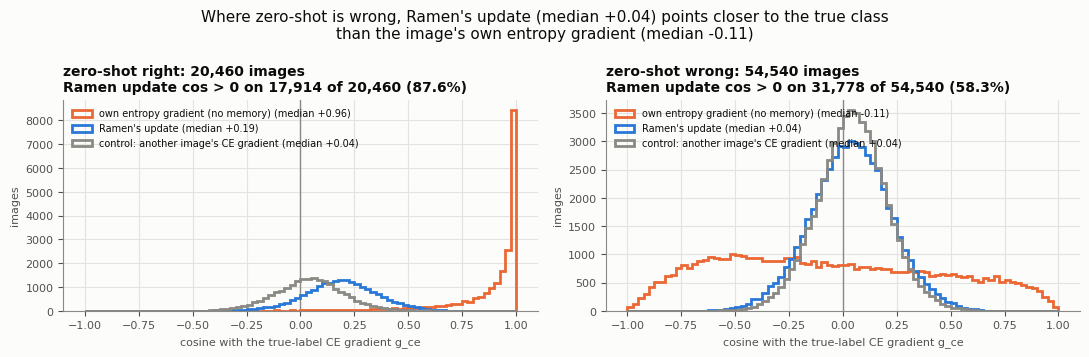

In [4]:
plot_cosine_distributions(df);
display(direction_summary(df, df['zs_ok'].map({True: 'zero-shot right', False: 'zero-shot wrong'})).round(3))

### 4.2 By outcome: images Ramen fixes, breaks, or leaves

Dumbbell per outcome group: orange = median cosine of the image's own entropy gradient, blue = of Ramen's update,
grey diamond = control. The line between them is what the memory changes.

,images,own entropy gradient (no memory),Ramen's update,control: another image's CE gradient,Ramen's sign step,sign agreement (step),sign agreement (own entropy),update cos > 0
outcome,,,,,,,,
both right,17600,0.970,0.203,0.045,0.050,0.574,0.984,"15,800 of 17,600 (89.8%)"
fixed by Ramen,7209,0.267,0.160,0.039,0.057,0.580,0.622,"6,310 of 7,209 (87.5%)"
broken by Ramen,2860,0.817,0.109,0.036,0.023,0.533,0.903,"2,114 of 2,860 (73.9%)"
both wrong,47331,-0.158,0.017,0.044,0.014,0.520,0.421,"25,468 of 47,331 (53.8%)"


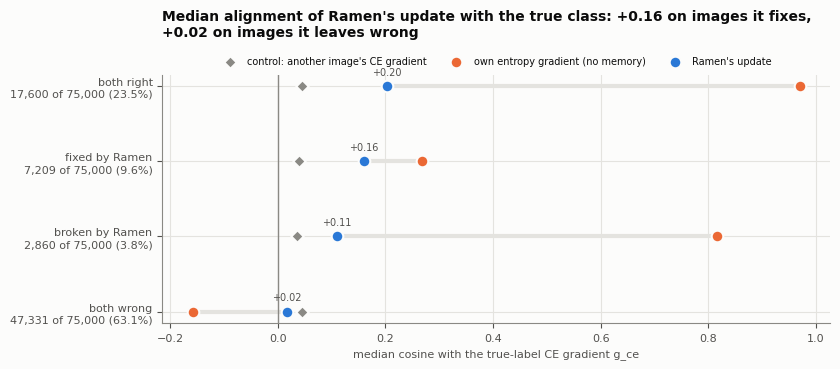

In [5]:
plot_outcome_dumbbell(df);
display(direction_summary(df, 'outcome').round(3))

### 4.3 By domain

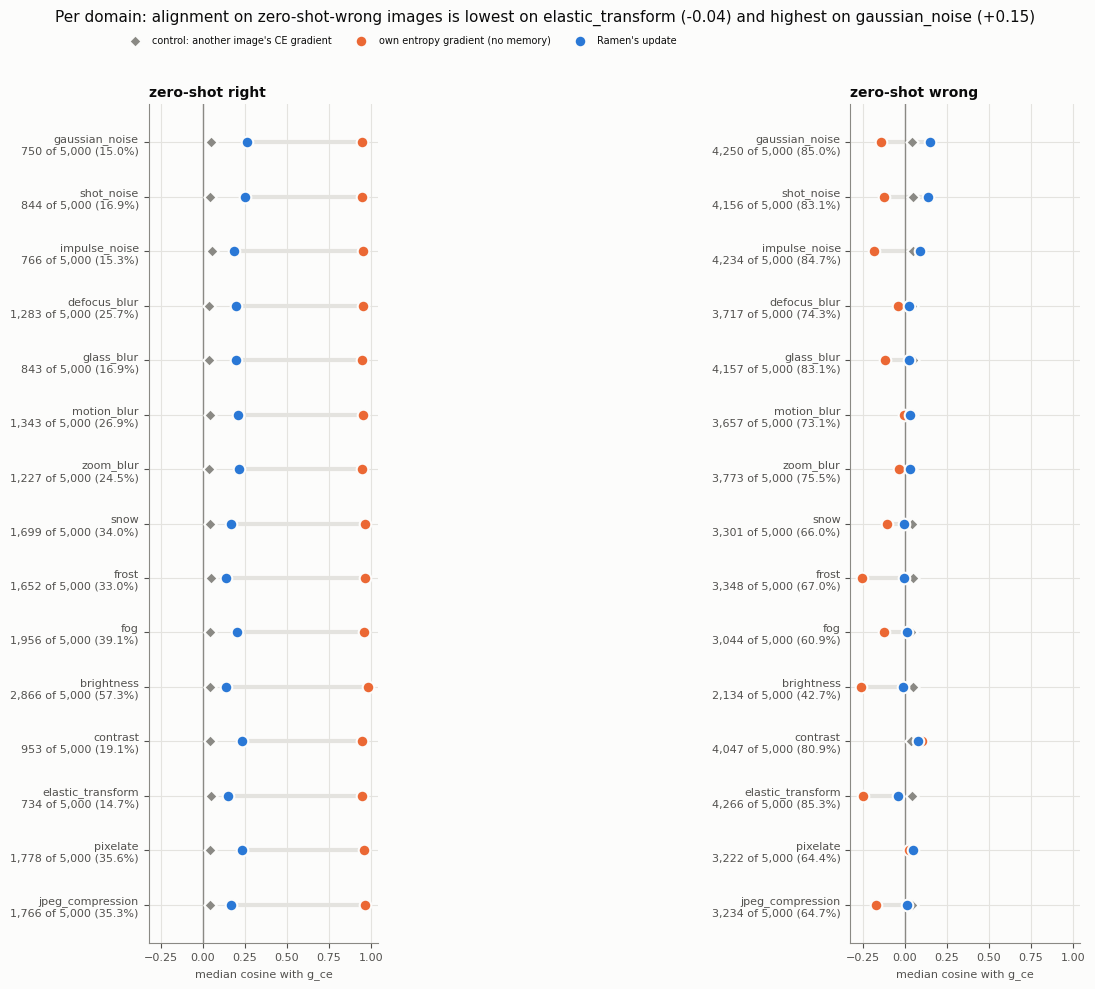

In [6]:
plot_domain_dumbbell(df);

### 4.4 Over the stream

Rolling mean over stream position. The dashed line marks where fewer than half of the images still get their own
entry stored (Ramen's fp16 arrival counter saturates after 65,520 inserts and full queues stop updating).

memory never freezes


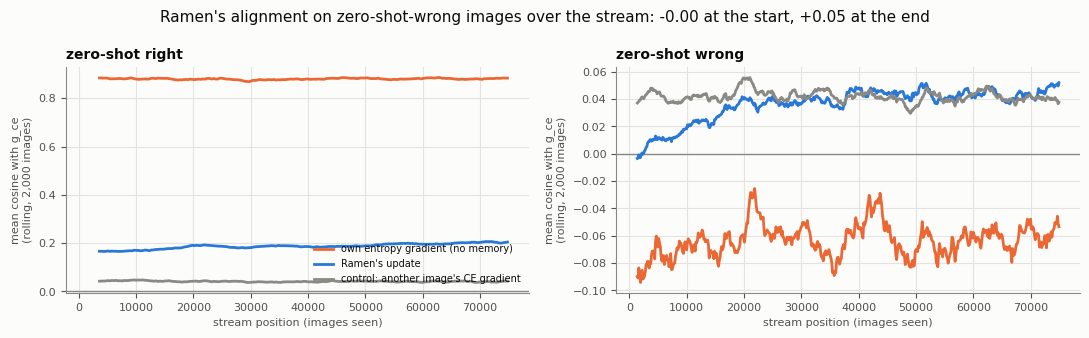

In [7]:
freeze = memory_freeze_position(df)
print(f'own entry stored for {int((df.part_self != 0).sum()):,} of {len(df):,} images; '
      f'mostly frozen from position {freeze:,}' if freeze else 'memory never freezes')
plot_stream(df, window=2_000, freeze_at=freeze);

## 5. Mechanism

### 5.1 Which memory entries make the update aligned?

The alignment $\cos(\hat g_i, g^{CE}_i)$ split exactly into the four parts of the update (section "Method"):
the image's own entry, other entries of the true-class queue, other entries of the wrong zero-shot-class queue, and
all other queues. Bars are means over images; the black tick is the total.

,images,part_self,part_true,part_zs,part_other,cos_update
outcome,,,,,,
both right,17600,0.015,-0.000,0.0,0.187,0.202
fixed by Ramen,7209,0.000,0.001,-0.0,0.162,0.164
broken by Ramen,2860,0.005,0.000,0.0,0.099,0.104
both wrong,47331,-0.001,0.000,-0.0,0.018,0.017


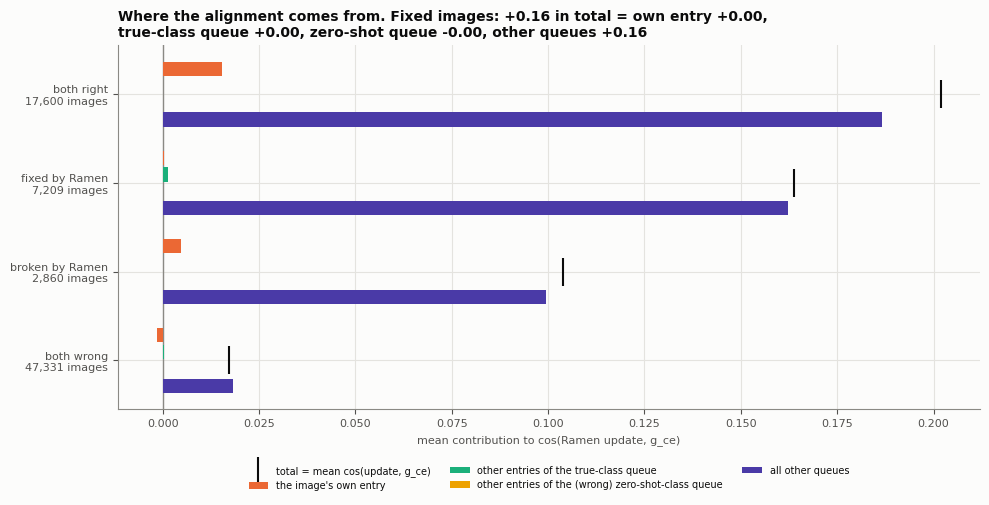

In [8]:
display(decomposition(df).round(3))
plot_decomposition(df);

### 5.2 Does alignment predict whether Ramen fixes or breaks an image?

Images are split into deciles of $\cos(\operatorname{sign} \hat g_i, g^{CE}_i)$ (the step Ramen takes) within each
zero-shot group. Left: share of zero-shot errors Ramen fixes; middle: share of zero-shot hits it breaks; right:
median change of $\log p(y_i)$ caused by the step. Counts in the end labels.

,group,bin,x,images,events,rate,dlogp_median
0,zero-shot right,"(-0.11, 0.00443]",-0.007,2046,863,0.422,-0.200
1,zero-shot right,"(0.00443, 0.0185]",0.012,2046,442,0.216,0.022
2,zero-shot right,"(0.0185, 0.0287]",0.024,2046,316,0.154,0.087
3,zero-shot right,"(0.0287, 0.0379]",0.033,2046,230,0.112,0.122
4,zero-shot right,"(0.0379, 0.047]",0.043,2046,222,0.109,0.177
5,zero-shot right,"(0.047, 0.0563]",0.051,2046,178,0.087,0.184
6,zero-shot right,"(0.0563, 0.0674]",0.062,2046,168,0.082,0.234
7,zero-shot right,"(0.0674, 0.0819]",0.074,2046,153,0.075,0.250
8,zero-shot right,"(0.0819, 0.103]",0.091,2046,173,0.085,0.285
9,zero-shot right,"(0.103, 0.238]",0.120,2046,115,0.056,0.285


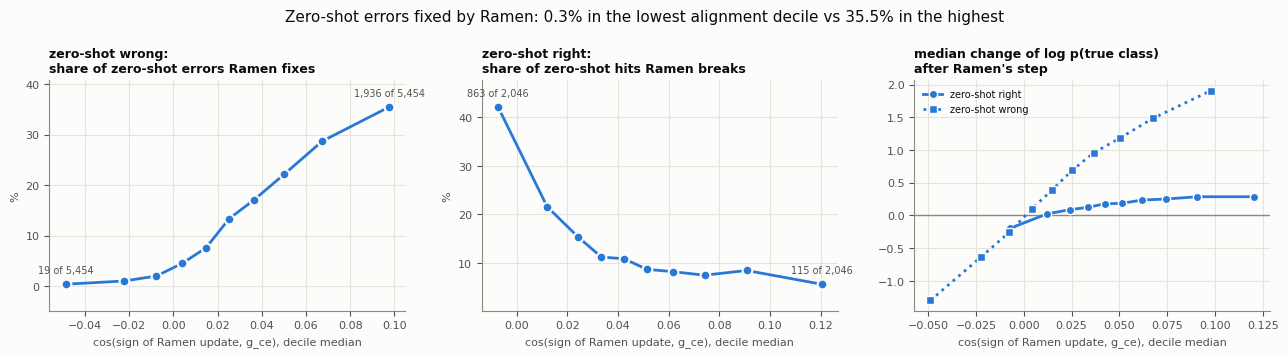

In [9]:
plot_outcome_vs_alignment(df);
display(binned_outcome_rates(df).round(3))

## 6. Pre-registered hypotheses

In [10]:
display(hypotheses(df))

,test,numbers,holds
hypothesis,,,
H1,"median cos(update, g_ce) > median control cos(...",+0.082 vs +0.044,True
H2,"zero-shot wrong: median cos(update, g_ce) > me...","+0.038 vs -0.108 (54,540 images)",True
H3a,zero-shot wrong: fix rate rises with cos(sign ...,fix rate 0.3% (lowest bin) -> 35.5% (highest);...,True
H3b,"images Ramen breaks: median cos(sign step, g_c...","+0.023 (2,860 images; zero-shot right overall ...",False


## 7. Interpretation (ImageNet-C 5K, seed 0, 75,000 images)

**In one line.** Same picture as DomainNet, weaker and more uniform. Where zero-shot is wrong, the memory turns a
mildly wrong own direction (median −0.11) into a mildly positive one (+0.038). That is still slightly below the
shuffled control (+0.043). Practically all of the alignment comes from "other queues": with 1,000 classes and
$k = 1$, the true-class queue contributes one entry out of ~974.

**What the numbers show.**
- **Zero-shot right (20,460 images, 27.3%).** Own entropy gradient 0.96, Ramen's update 0.19 (positive on 17,914 of
  20,460 = 87.6%). Breaks: 2,860 (14.0% of these images).
- **Zero-shot wrong (54,540 images, 72.7%).** Own entropy gradient −0.11, Ramen's update +0.038 (positive on 31,778
  of 54,540 = 58.3%), sign agreement 52.9%, slightly above chance. H2 holds. The update is not above the control
  (+0.043), so it is no more about *this* image's true class than about another image's.
- **Fixed (7,209) vs broken (2,860).** Unlike DomainNet and EuroSAT, fixed images already had a *positive* own
  direction (+0.27): many ImageNet-C fixes are images whose true class was close behind the zero-shot one. Ramen
  keeps part of it (+0.16). Broken images lose a good own direction (+0.82 → +0.11). Their sign step is +0.023,
  not negative, so H3b fails as on DomainNet.
- **Alignment decides the outcome (H3a).** The fix rate rises from 0.3% (19 of 5,454) in the lowest decile of
  cos(sign step, g_ce) to 35.5% (1,936 of 5,454) in the highest. The break rate falls from 42.2% (863 of 2,046) to
  5.6% (115 of 2,046).
- **Where the alignment comes from.** Fixed images: +0.164 in total, of which other queues +0.162, true-class queue
  +0.001, own entry +0.000. The zero-shot queue part is exactly 0. With $k = 1$ an image's own entry is the
  nearest in its zero-shot queue (distance 0), so no other entry of that queue is retrieved. The own entry gets
  weight 1/974 and adds nothing.
- **Corruptions.** The zero-shot-wrong median ranges from −0.04 (elastic_transform) to +0.15 (gaussian_noise). The
  three noise corruptions are the only ones clearly above the control, and they are also where 83–85% of images
  are wrong at zero-shot.
- **Over the stream.** On zero-shot-wrong images the alignment rises from about 0.00 to about +0.05, crossing the
  control at about 40,000 images. Each photo appears 15 times (once per corruption). Later copies may therefore
  find an earlier copy of the *same photo* in another queue, which carries that photo's information. This fits
  the same-photo leak seen in the label-value oracle (2026-11-02), but this run did not log which entries were
  retrieved, so it is a **hypothesis**. The memory does not freeze: own entry stored for 74,465 of 75,000 images.

**What this does not show.**
- One seed. Cosines are small in absolute terms (random directions: about ±0.005).
- Whether the late rise on zero-shot-wrong images is a same-photo effect. Testing it needs the retrieved entries'
  photo ids, or a run with `exclude_groups`.
- Zero-shot = the prediction Ramen filed each image under. It differs from the cached NoAdapt run on 260 of 75,000
  images (0.35%, fp16 near-ties).

**Next step.** Compare across datasets (README): the true-class queue's share shrinks with the number of classes.


## 8. Glossary

| Term | Meaning |
|---|---|
| Ramen | Test-time adaptation for CLIP: per-class memory of past images' entropy gradients; each image takes one SignSGD step along a weighted average of retrieved gradients, predicts, and resets |
| zero-shot | CLIP's prediction without adaptation ($\hat y_i$); Ramen files each image in this class's queue |
| $g^{CE}$ (oracle gradient) | gradient of the cross-entropy toward the **true** label; uses ground truth, so it is a measuring stick, not something a method can use |
| own entropy gradient $g_i$ | gradient of the image's own prediction entropy; minimising it sharpens the current prediction, right or wrong |
| Ramen's update $\hat g_i$ | the retrieved, weighted average of stored entropy gradients that Ramen steps along |
| sign step | Ramen moves by $-\eta\,\mathrm{sign}(\hat g_i)$, so only the sign of each coordinate matters for the step |
| cosine similarity | $\langle a, b\rangle / (\lVert a\rVert \lVert b\rVert)$, from −1 (opposite) through 0 (unrelated) to +1 (same direction) |
| sign agreement | share of $\lvert g^{CE}\rvert$ mass on coordinates where the sign step moves the same way as the oracle; 0.5 = chance |
| shuffled control | cosine of an image's update with *another* image's $g^{CE}$; alignment shared by all images, not specific to the true class |
| own entry | the image's own memory entry, written before retrieval and retrieved at distance ≈ 0 |
| fixed / broken | zero-shot wrong → Ramen right / zero-shot right → Ramen wrong |
| fp16 freeze | Ramen's arrival counter is stored in fp16 and saturates after 65,520 images; full queues then stop accepting new entries |
| pooled accuracy | correct images / all images (here), as opposed to the domain-averaged accuracy used for headline numbers |
